In [1]:
from Zn import Zn, ZnElement
from UnitGroup import UnitGroupElement
from PairRing import PairRing, PairElement

In [2]:
def diffie_hellman(g, a, b):
    # Simuliert den Schluesselaustausch fuer ein Gruppenelement g.
    P_A = g.power(a)
    # A berechnet g^a und sendet es an B
    P_B = g.power(b)
    # B berechnet g^b und sendet es an A
    K_A = P_B.power(a)
    # A berechnet (g^b)^a
    K_B = P_A.power(b)
    # B berechnet (g^a)^b
    assert K_A == K_B
    return K_A

In [3]:
R = Zn(7)
x = ZnElement(3, 7)
y = ZnElement(5, 7)
print(x.add(y), x.multiply(y), x.subtract(y))  # Ausgabe: 1 1 5
print(len(R.enum()))  # Ausgabe: 7

1 1 5
7


In [4]:
g = UnitGroupElement(ZnElement(5, 23))
print(diffie_hellman(g, 6, 15))
# Ausgabe: 2 (wie im Beispiel von Hand)
print(Zn(6).units().order())
# Ausgabe: 2 (die Einheiten 1 und 5)
print(ZnElement(2, 7).inverse())
# Ausgabe: 4 (denn 2*4 = 8 = 1 in Z_7)

2
2
4


In [5]:
# Aufgabe 1.3.3
# Test ob len angegebene Länge gibt
print(len(PairRing().enum()))
print(PairRing().enum())

9
[(0, 0), (0, 1), (0, 2), (1, 0), (1, 1), (1, 2), (2, 0), (2, 1), (2, 2)]


In [6]:
# Aufgabe 1.3.4
# Ring Axiome + Abelsche Gruppe Axiome
R = PairRing()
E = R.enum()
one = R.one()
zero = R.zero()
for a in E:
    # R1.AG3 a + e = a = e + a
    assert a.add(zero) == a

    # R1.AG4 a + a^-1 = e
    assert a.add(a.additive_inverse()) == zero

    # R4 1 * a = a
    assert one.multiply(a) == a
    for b in E:
        # R1.AG2 a + b = b + a
        assert a.add(b) == b.add(a)

        # R3 a * b = b * a
        assert a.multiply(b) == b.multiply(a)
        for c in E:
            # R1.AG1 (a + b) + c = a + (b + c)
            assert (a.add(b)).add(c) == a.add(b.add(c))

            # R2 (a * b) * c = a * (b * c)
            assert a.multiply(b).multiply(c) == a.multiply(b.multiply(c))

            # R5
            links = a.multiply(b.add(c))  # a * (b + c)
            rechts = a.multiply(b).add(a.multiply(c))  # a * b + a * c
            assert links == rechts

In [7]:
# Aufgabe 1.3.4 Fortführung
# Überprüfung der Handrechnungen
a = PairElement(1, 1)
b = PairElement(1, 1)
result = a.multiply(b)

print(f"{a} * {b} = {result}")

a = PairElement(1, 2)
b = PairElement(1, 1)
result = a.multiply(b)

print(f"{a} * {b} = {result}")

a = PairElement(0, 1)
b = PairElement(0, 1)
result = a.multiply(b)

print(f"{a} * {b} = {result}")

a = PairElement(0, 1)
b = PairElement(0, 2)
result = a.multiply(b)

print(f"{a} * {b} = {result}\n")

a = PairElement(1, 0)
for i in range(3):
    for j in range(3):
        b = PairElement(j, i)
        result = a.multiply(b)

        print(f"{a} * {b} = {result}")

(1, 1) * (1, 1) = (0, 2)
(1, 2) * (1, 1) = (2, 0)
(0, 1) * (0, 1) = (2, 0)
(0, 1) * (0, 2) = (1, 0)

(1, 0) * (0, 0) = (0, 0)
(1, 0) * (1, 0) = (1, 0)
(1, 0) * (2, 0) = (2, 0)
(1, 0) * (0, 1) = (0, 1)
(1, 0) * (1, 1) = (1, 1)
(1, 0) * (2, 1) = (2, 1)
(1, 0) * (0, 2) = (0, 2)
(1, 0) * (1, 2) = (1, 2)
(1, 0) * (2, 2) = (2, 2)


In [8]:
# Aufgabe 1.3.5
# alle Einheiten mit Inverse bestimmen
R = PairRing()
E = R.enum()
for a in E:
    if a.is_unit():
        print(f"Unit: {a}, Inv: {a.inverse()}")

Unit: (0, 1), Inv: (0, 2)
Unit: (0, 2), Inv: (0, 1)
Unit: (1, 0), Inv: (1, 0)
Unit: (1, 1), Inv: (2, 1)
Unit: (1, 2), Inv: (2, 2)
Unit: (2, 0), Inv: (2, 0)
Unit: (2, 1), Inv: (1, 1)
Unit: (2, 2), Inv: (1, 2)


In [9]:
# Aufgabe 1.4.1
R = PairRing()
R.units().order()

8

In [10]:
# Aufgabe 1.4.2
Z9 = Zn(9)
Z9.units().order()

6

In [11]:
# Aufgabe 1.4.3
Z9 = Zn(9)
Z9_E = Z9.enum()
for a in Z9_E:
    if a.is_unit():
        print(f"Unit: {a}, Inv: {a.inverse()}")

Unit: 1, Inv: 1
Unit: 2, Inv: 5
Unit: 4, Inv: 7
Unit: 5, Inv: 2
Unit: 7, Inv: 4
Unit: 8, Inv: 8


In [12]:
# Aufgabe 1.4.3 Fortführung
# null Elemente ohne null bei Z9 berechnen
Z9 = Zn(9)
Z9_E = Z9.enum()
Z9_zero = Z9.zero()
for a in Z9_E:
    for b in Z9_E:
        if a == Z9_zero or b == Z9_zero:
            continue
        result = a.multiply(b)
        if result == Z9_zero:
            print(f"{a} * {b} = {result}")

3 * 3 = 0
3 * 6 = 0
6 * 3 = 0
6 * 6 = 0


In [13]:
# Aufgabe 1.4.3 Fortführung
# null Elemente ohne null bei M berechnen
R = PairRing()
E = R.enum()
zero = R.zero()
for a in E:
    for b in E:
        if a == zero or b == zero:
            continue
        result = a.multiply(b)
        if result == zero:
            print(f"{a} * {b} = {result}")

## Weiterer Code aus Vorlesung

In [14]:
def test_abelian_group(G, max_exponent=4):
    elements = G.enum()
    e = G.identity()
    for x in elements:
        assert x.multiply(e) == x  # AG3
        assert x.multiply(x.inverse()) == e  # AG4
        for y in elements:
            assert x.multiply(y) == y.multiply(x)  # AG2
            for z in elements:
                assert x.multiply(y).multiply(z) == x.multiply(y.multiply(z))  # AG1
    for x in elements:
        for y in elements:
            for r in range(max_exponent):
                xy_r = x.multiply(y).power(r)
                assert xy_r == x.power(r).multiply(y.power(r))  # I
                for s in range(max_exponent):
                    assert x.power(r + s) == x.power(r).multiply(x.power(s))  # II
                    assert x.power(r).power(s) == x.power(r * s)  # III
    print('Alle Tests bestanden.')

In [15]:
test_abelian_group(Zn(7).units())
test_abelian_group(Zn(12).get_additive_group())

Alle Tests bestanden.
Alle Tests bestanden.


In [16]:
def order(x):
    # Die Ordnung eines Elements x einer endlichen abelschen Gruppe.
    e = x.identity()
    y = x
    n = 1
    while y != e:
        y = y.multiply(x)
        n += 1
    return n

In [17]:
G = Zn(19).units()
print([order(x) for x in G.enum()])

[1, 18, 18, 9, 9, 9, 3, 6, 9, 18, 3, 6, 18, 18, 18, 9, 9, 2]


In [18]:
def order_statistics(n):
    # Ordnungen aller Elemente der Einheitengruppe von Z_n.
    G = Zn(n).units()
    elements = G.enum()
    orders = [order(x) for x in elements]
    return {'n': n,
            'Anzahl Einheiten': len(elements),
            'maximale Ordnung': max(orders),
            'mittlere Ordnung': sum(orders) / len(orders)}


def plot_orders(n):
    # Zeichnet zu jeder Einheit g von Z_n ihre Ordnung ord(g).
    import matplotlib.pyplot as plt
    G = Zn(n).units()
    xs = [x.r.value for x in G.enum()]  # der Wert der Einheit als Zahl
    ys = [order(x) for x in G.enum()]
    plt.scatter(xs, ys)
    plt.xlabel('Einheit g')
    plt.ylabel('ord(g)')
    plt.show()

In [19]:
print(order_statistics(60))
print(order_statistics(61))

{'n': 60, 'Anzahl Einheiten': 16, 'maximale Ordnung': 4, 'mittlere Ordnung': 2.9375}
{'n': 61, 'Anzahl Einheiten': 60, 'maximale Ordnung': 60, 'mittlere Ordnung': 26.95}


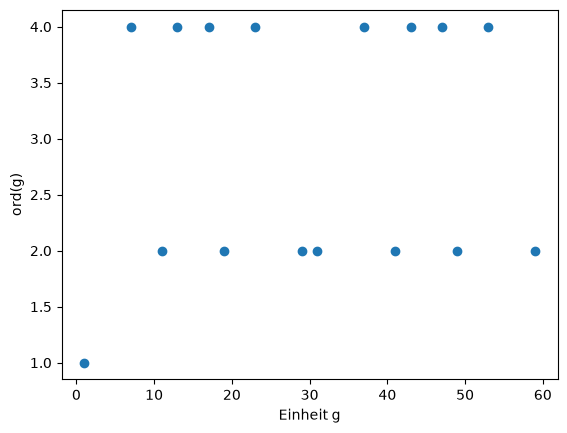

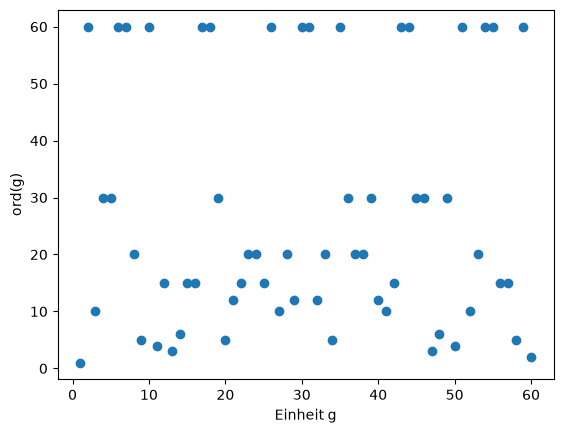

In [20]:
plot_orders(60)
plot_orders(61)